<a href="https://colab.research.google.com/github/starsyntaxx/MarketIQ/blob/main/notebooks/01_data_understanding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import zipfile
import os

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

In [3]:

def extract_file_from_drive(zip_path, file_name, extract_to='/content/extracted'):

    os.makedirs(extract_to, exist_ok=True)

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:

        if file_name not in zip_ref.namelist():
            raise FileNotFoundError(
                f"{file_name} not found in the ZIP archive."
            )

        zip_ref.extract(file_name, extract_to)

    extracted_path = os.path.join(extract_to, file_name)

    return extracted_path

In [4]:
zip_path = "/content/drive/MyDrive/ML PROJECTS/MarketIQ/data/raw/NGA_2025_HFCP_v01_M_CSV.zip"

In [5]:
import zipfile

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    print(zip_ref.namelist())

['Raw_data_spatialrev.csv', 'level2_price_yellow_maize.csv', 'level2_price_yam.csv', 'level2_price_white_maize.csv', 'level2_price_white_beans.csv', 'level2_price_soybean.csv', 'level2_price_sorghum.csv', 'level2_price_local_rice.csv', 'level2_price_imported_rice.csv', 'level2_price_garri.csv', 'level2_price_brown_beans.csv']


In [6]:
file_path = extract_file_from_drive(
    zip_path=zip_path,
    file_name='level2_price_white_beans.csv'
)

print(file_path)

/content/extracted/level2_price_white_beans.csv


In [7]:
import pandas as pd

df = pd.read_csv(file_path)

df.head().T

,0,1,2,3,4
fid,6,7,9,16,17
submissio,6538,6539,6635,11821,11825
date,12/3/2024,12/3/2024,12/3/2024,12/8/2024,12/8/2024
zonecode1,5,5,3,1,1
geopol_zon,nbssouthsouth,nbssouthsouth,nbsnorthwest,nbsnorthcentral,nbsnorthcentral
statecode1,6,6,20,25,25
zonelabel1,South South,South South,North West,North Central,North Central
statelabel,BAYELSA,BAYELSA,KATSINA,NASARAWA,NASARAWA
lga,603,603,2021,2504,2504
lgalabel,KOLOKUMA/OPOKUMA,KOLOKUMA/OPOKUMA,KATSINA,KARU,KARU


## Dataset Variable Description

The dataset contains the following variables and their corresponding descriptions:

| ID | Variable Name | Description |
|:---|:---|:---|
| V1 | `fid` | Field ID for the data record, based on the overall dataset. |
| V2 | `submissio` | System-assigned submission ID for each price data record. |
| V3 | `date` | Date of data submission. |
| V4 | `zonecode1` | Officially assigned code for the geopolitical zone. |
| V5 | `geopol_zon` | Assigned codename for the geopolitical zone. |
| V6 | `statecode1` | Assigned code for the state. |
| V7 | `zonelabel1` | Geopolitical zone. |
| V8 | `statelabel` | Name of the administrative state. |
| V9 | `lga` | Assigned ID for the Local Government Area (LGA). |
| V10 | `lgalabel` | Name of the Local Government Area (LGA). |
| V11 | `sector` | Binary coding for the geographical context (rural or urban). |
| V12 | `staff_vali` | Number that differentiates crowdsourced data from validation data. |
| V13 | `consent` | Number indicating whether the vendor consents to providing price data. |
| V14 | `market_typ` | Type of market where price data was sourced. |
| V15 | `price_cate` | Market segment of the price outlet. |
| V16 | `market_tim` | Estimated travel time to the market outlet, in minutes. |
| V18 | `gps_latitu` | Geographic GPS latitude. |
| V19 | `gps_longit` | Geographic GPS longitude. |
| V20 | `count` | Dummy unitary variable for counting data records. |
| V22 | `month` | Month of data submission. |
| V24 | `price` | Observed price calculated per kilogram, in Nigerian Naira (₦). |
| V25 | `commodity` | Name of the commodity. |
| V26 | `daily_mean` | Calculated mean of all price submissions made during a specific day, in Naira per kilogram. |
| V27 | `daily_sd` | Calculated standard deviation of all price submissions made during a specific day. |
| V28 | `outlier_flag` | Outlier designation based on 2.5 times the standard deviation. |

### Notes
- Prices are expressed in Nigerian Naira (₦) per kilogram.
- Geographic variables provide information about the location of each market.
- `staff_vali` helps distinguish crowdsourced submissions from validation data.
- `daily_mean` and `daily_sd` provide daily statistical summaries of commodity prices.
- `outlier_flag` identifies potentially unusual price observations based on the standard deviation threshold.

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202059 entries, 0 to 202058
Data columns (total 25 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   fid           202059 non-null  int64  
 1   submissio     202059 non-null  int64  
 2   date          202059 non-null  object 
 3   zonecode1     202059 non-null  int64  
 4   geopol_zon    202059 non-null  object 
 5   statecode1    202059 non-null  int64  
 6   zonelabel1    202059 non-null  object 
 7   statelabel    202059 non-null  object 
 8   lga           202059 non-null  int64  
 9   lgalabel      202059 non-null  object 
 10  sector        202059 non-null  object 
 11  staff_vali    202059 non-null  int64  
 12  consent       202059 non-null  int64  
 13  market_typ    202059 non-null  object 
 14  price_cate    202059 non-null  object 
 15  market_tim    202059 non-null  int64  
 16  gps_latitu    202059 non-null  float64
 17  gps_longit    202059 non-null  float64
 18  coun

In [9]:
df.describe()

,fid,submissio,zonecode1,statecode1,lga,staff_vali,consent,market_tim,gps_latitu,gps_longit,count,price,daily_mean,daily_sd
count,202059.000000,202059.000000,202059.000000,202059.000000,202059.000000,202059.000000,202059.0,2.020590e+05,202059.000000,202059.000000,202059.0,202059.000000,202059.000000,202059.000000
mean,109860.418383,115990.081070,3.432824,19.613791,1972.844832,0.111062,1.0,6.062553e+03,8.660558,7.310543,1.0,1701.729641,1799.357333,748.497657
std,63409.028481,62079.298111,1.778112,10.288456,1027.844088,0.314209,0.0,1.912650e+06,2.493766,2.471863,0.0,537.485659,125.974258,48.557732
min,6.000000,6249.000000,1.000000,1.000000,101.000000,0.000000,1.0,-8.500000e+01,4.426009,2.714769,1.0,100.000000,1608.639962,624.704217
25%,54859.500000,62551.500000,2.000000,11.000000,1104.000000,0.000000,1.0,1.000000e+01,6.573922,5.249431,1.0,1250.000000,1698.680360,718.796247
50%,109903.000000,116203.000000,3.000000,20.000000,2020.000000,0.000000,1.0,2.000000e+01,8.165061,7.367033,1.0,1678.571429,1733.014010,747.071268
75%,164636.500000,169656.500000,5.000000,29.000000,2902.000000,0.000000,1.0,4.000000e+01,10.649415,8.539809,1.0,2000.000000,1935.207221,779.002383
max,220213.000000,223519.000000,6.000000,37.000000,3706.000000,1.000000,1.0,6.584807e+08,13.754103,14.209325,1.0,4285.714286,2058.411893,932.402245


### 1. Data Cleaning & Temporal Alignment
Let's convert the `date` column to datetime and check the date range of our dataset.

In [10]:
df['date'] = pd.to_datetime(df['date'])
print(f"Data Date Range: {df['date'].min()} to {df['date'].max()}")

Data Date Range: 2024-12-03 00:00:00 to 2025-06-29 00:00:00


### 2. Checking Anomalies
Let's check the distribution of the travel time (`market_tim`) and filter out anomalous records (e.g., extremely high travel times or negative values) to understand our operational boundaries.

In [11]:
negative_times = (df['market_tim'] < 0).sum()
extreme_times = (df['market_tim'] > 480).sum()  # over 8 hours
print(f"Submissions with negative market travel times: {negative_times}")
print(f"Submissions with > 8 hours travel time: {extreme_times}")

Submissions with negative market travel times: 14
Submissions with > 8 hours travel time: 206


### 3. Baseline Summary by Geopolitical Zone
Let's group by geopolitical zone to analyze the volume of records, average price, and average travel time.

In [12]:
zone_summary = df.groupby('zonelabel1').agg(
    record_count=('fid', 'count'),
    mean_price=('price', 'mean'),
    median_price=('price', 'median'),
    mean_travel_time=('market_tim', 'mean')
).reset_index().sort_values(by='mean_price', ascending=False)

display(zone_summary)

,zonelabel1,record_count,mean_price,median_price,mean_travel_time
3,South East,20183,2089.256867,2000.000000,32693.347272
4,South South,29008,2080.691385,2000.000000,259.220456
2,North West,44261,1760.539919,1785.714286,33.182621
1,North East,30102,1651.751179,1714.285714,33.970135
5,South West,39276,1454.875400,1250.000000,31.968683
0,North Central,39229,1441.272144,1428.571429,14119.077927


### 4. Baseline Visualizations
We'll visualize the overall distribution of price per kg and display average price comparisons across different regions.

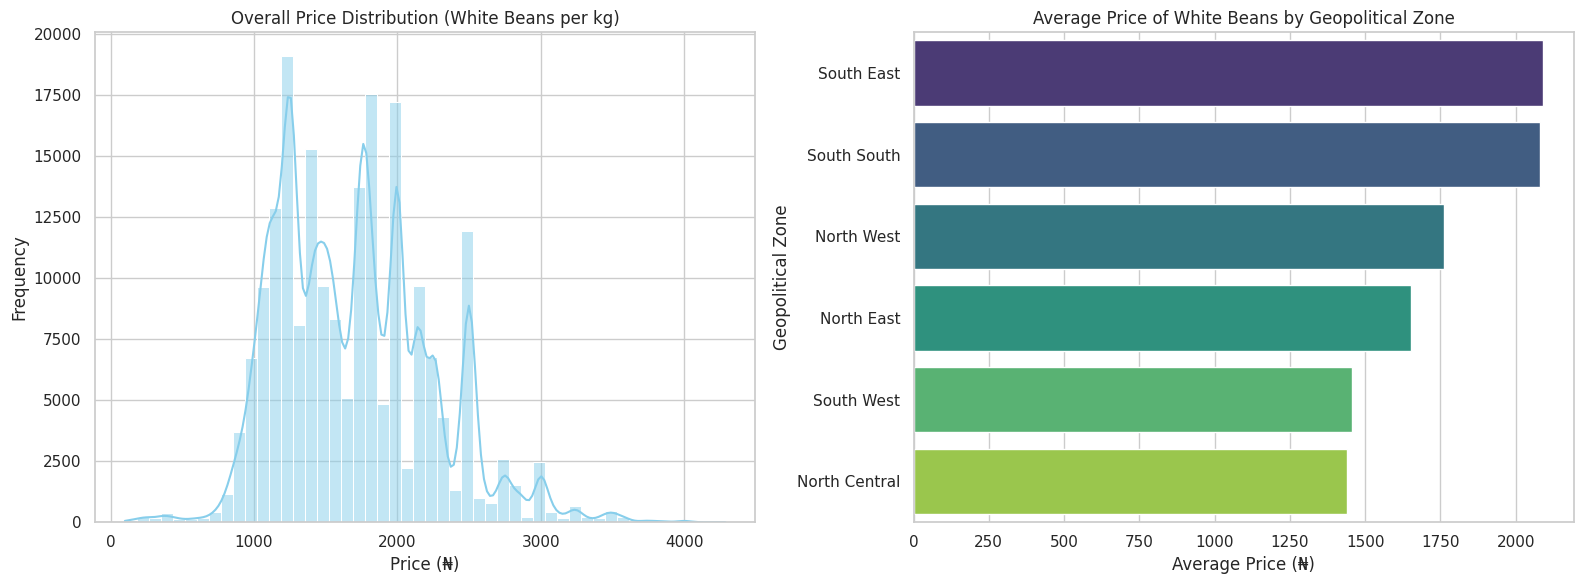

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Price Distribution
sns.histplot(df['price'], bins=50, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Overall Price Distribution (White Beans per kg)')
axes[0].set_xlabel('Price (₦)')
axes[0].set_ylabel('Frequency')

# Subplot 2: Average Price by Geopolitical Zone
sns.barplot(x='mean_price', y='zonelabel1', data=zone_summary, ax=axes[1], palette='viridis', hue='zonelabel1', legend=False)
axes[1].set_title('Average Price of White Beans by Geopolitical Zone')
axes[1].set_xlabel('Average Price (₦)')
axes[1].set_ylabel('Geopolitical Zone')

plt.tight_layout()
plt.show()

### 5. Price Trends Over Time Across Geopolitical Zones
To observe how prices fluctuate chronologically in each region, we will aggregate the dataset by week and geopolitical zone, and plot the average price trends.

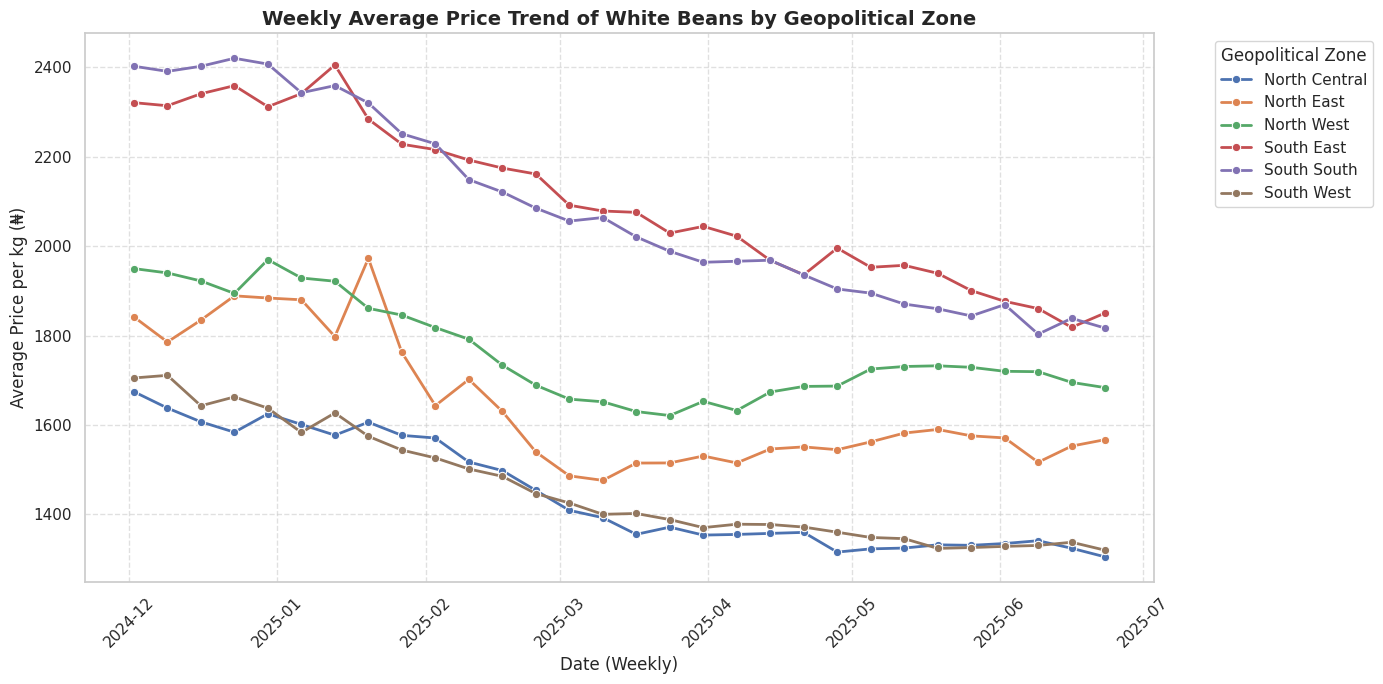

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure 'date' is converted to datetime in case the DataFrame was reloaded
df['date'] = pd.to_datetime(df['date'])

# Group by geopolitical zone and week
df['week'] = df['date'].dt.to_period('W').dt.to_timestamp()
trend_df = df.groupby(['week', 'zonelabel1'])['price'].mean().reset_index()

# Create the trend line plot
plt.figure(figsize=(14, 7))
sns.lineplot(data=trend_df, x='week', y='price', hue='zonelabel1', marker='o', linewidth=2)

plt.title('Weekly Average Price Trend of White Beans by Geopolitical Zone', fontsize=14, fontweight='bold')
plt.xlabel('Date (Weekly)', fontsize=12)
plt.ylabel('Average Price per kg (₦)', fontsize=12)
plt.legend(title='Geopolitical Zone', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202059 entries, 0 to 202058
Data columns (total 26 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   fid           202059 non-null  int64         
 1   submissio     202059 non-null  int64         
 2   date          202059 non-null  datetime64[ns]
 3   zonecode1     202059 non-null  int64         
 4   geopol_zon    202059 non-null  object        
 5   statecode1    202059 non-null  int64         
 6   zonelabel1    202059 non-null  object        
 7   statelabel    202059 non-null  object        
 8   lga           202059 non-null  int64         
 9   lgalabel      202059 non-null  object        
 10  sector        202059 non-null  object        
 11  staff_vali    202059 non-null  int64         
 12  consent       202059 non-null  int64         
 13  market_typ    202059 non-null  object        
 14  price_cate    202059 non-null  object        
 15  market_tim    202

**Selected features to build baseline model**

### 6. Standardizing and Normalizing Column Names and Text Values
Let's format all column headers and string contents in the DataFrame to be entirely lowercase with underscores instead of spaces.

In [16]:
# 1. Normalize Column Names
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# 2. Normalize Text/String Values in Object Columns
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].astype(str).str.strip().str.lower().str.replace(' ', '_')

# Display the standardized column list and top rows to verify changes
print("Standardized Columns:", df.columns.tolist())
display(df.head())

Standardized Columns: ['fid', 'submissio', 'date', 'zonecode1', 'geopol_zon', 'statecode1', 'zonelabel1', 'statelabel', 'lga', 'lgalabel', 'sector', 'staff_vali', 'consent', 'market_typ', 'price_cate', 'market_tim', 'gps_latitu', 'gps_longit', 'count', 'month', 'price', 'commodity', 'daily_mean', 'daily_sd', 'outlier_flag', 'week']


,fid,submissio,date,zonecode1,geopol_zon,statecode1,zonelabel1,statelabel,lga,lgalabel,...,gps_latitu,gps_longit,count,month,price,commodity,daily_mean,daily_sd,outlier_flag,week
0,6,6538,2024-12-03,5,nbssouthsouth,6,south_south,bayelsa,603,kolokuma/opokuma,...,5.127898,6.296028,1,dec,1860.000000,white_beans,1998.126814,728.108298,non-outlier,2024-12-02
1,7,6539,2024-12-03,5,nbssouthsouth,6,south_south,bayelsa,603,kolokuma/opokuma,...,5.127898,6.296028,1,dec,1800.000000,white_beans,1998.126814,728.108298,non-outlier,2024-12-02
2,9,6635,2024-12-03,3,nbsnorthwest,20,north_west,katsina,2021,katsina,...,12.980655,7.585523,1,dec,2000.000000,white_beans,1998.126814,728.108298,non-outlier,2024-12-02
3,16,11821,2024-12-08,1,nbsnorthcentral,25,north_central,nasarawa,2504,karu,...,9.027698,7.600418,1,dec,1785.714286,white_beans,1967.629207,682.166115,non-outlier,2024-12-02
4,17,11825,2024-12-08,1,nbsnorthcentral,25,north_central,nasarawa,2504,karu,...,9.027698,7.600418,1,dec,1928.571429,white_beans,1967.629207,682.166115,non-outlier,2024-12-02


### 7. Constructing the Baseline Modeling Dataset (`model_df`)
We will filter our main DataFrame to include only the specified baseline features: `date`, `geopol_zon`, `statelabel`, `lgalabel`, `staff_vali`, `market_typ`, `price_cate`, `market_tim`, `month`, and the target variable `price`.

In [17]:
# Define the specified baseline features (using normalized lowercase column names)
baseline_features = [
    'date',
    'geopol_zon',
    'statelabel',
    'lgalabel',
    'staff_vali',
    'market_typ',
    'price_cate',
    'market_tim',
    'month',
    'price'
]

# Create model_df with a copy of these features
model_df = df[baseline_features].copy()

# Print information and display the first few rows to confirm
print("Shape of model_df:", model_df.shape)
print("\nFeatures and Data Types:")
print(model_df.dtypes)

display(model_df.head())

Shape of model_df: (202059, 10)

Features and Data Types:
date          datetime64[ns]
geopol_zon            object
statelabel            object
lgalabel              object
staff_vali             int64
market_typ            object
price_cate            object
market_tim             int64
month                 object
price                float64
dtype: object


,date,geopol_zon,statelabel,lgalabel,staff_vali,market_typ,price_cate,market_tim,month,price
0,2024-12-03,nbssouthsouth,bayelsa,kolokuma/opokuma,0,bulk_and_discount_stores,wholesale,15,dec,1860.000000
1,2024-12-03,nbssouthsouth,bayelsa,kolokuma/opokuma,0,open_air_or_covered_market,retail,20,dec,1800.000000
2,2024-12-03,nbsnorthwest,katsina,katsina,0,roadside_shops_street_vendors,retail,2,dec,2000.000000
3,2024-12-08,nbsnorthcentral,nasarawa,karu,0,city_market,retail,10,dec,1785.714286
4,2024-12-08,nbsnorthcentral,nasarawa,karu,0,city_market,retail,8,dec,1928.571429


In [18]:
for col in model_df.columns:
    num_unique = model_df[col].nunique()
    print(f"Column: {col} | Number of Unique Values: {num_unique}")
    if num_unique < 20:
        print(f"Unique values: {model_df[col].unique()}\n")
    else:
        print(f"Sample unique values: {list(model_df[col].unique()[:5])}\n")

Column: date | Number of Unique Values: 209
Sample unique values: [Timestamp('2024-12-03 00:00:00'), Timestamp('2024-12-08 00:00:00'), Timestamp('2024-12-12 00:00:00'), Timestamp('2024-12-14 00:00:00'), Timestamp('2024-12-15 00:00:00')]

Column: geopol_zon | Number of Unique Values: 6
Unique values: ['nbssouthsouth' 'nbsnorthwest' 'nbsnorthcentral' 'nbssoutheast'
 'nbsnortheast' 'nbssouthwest']

Column: statelabel | Number of Unique Values: 37
Sample unique values: ['bayelsa', 'katsina', 'nasarawa', 'enugu', 'kano']

Column: lgalabel | Number of Unique Values: 587
Sample unique values: ['kolokuma/opokuma', 'katsina', 'karu', 'enugu_south', 'tofa']

Column: staff_vali | Number of Unique Values: 2
Unique values: [0 1]

Column: market_typ | Number of Unique Values: 9
Unique values: ['bulk_and_discount_stores' 'open_air_or_covered_market'
 'roadside_shops_street_vendors' 'city_market' 'neighborhood_shops_kiosk'
 'local_village_market' 'supermarket' 'directly_from_farmer'
 'specialized_stor

In [19]:
model_df.groupby('staff_vali')['price'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
staff_vali,,,,
0,179618,1705.115116,1700.0,537.878291
1,22441,1674.632269,1562.5,533.571052


### 9. Temporal Relationship Analysis between Staff Validation (0 vs 1)
Let's analyze the dates associated with crowdsourced submissions (`staff_vali = 0`) versus staff validation submissions (`staff_vali = 1`). We will look at date ranges, distinct active days, and temporal overlap.

In [20]:
# Extract unique dates for each group
dates_group_0 = set(model_df[model_df['staff_vali'] == 0]['date'])
dates_group_1 = set(model_df[model_df['staff_vali'] == 1]['date'])

print(f"--- Group 0 (Crowdsourced): {len(dates_group_0)} unique days ---")
print(f"Date Range: {min(dates_group_0).strftime('%Y-%m-%d')} to {max(dates_group_0).strftime('%Y-%m-%d')}")

print(f"\n--- Group 1 (Validation): {len(dates_group_1)} unique days ---")
print(f"Date Range: {min(dates_group_1).strftime('%Y-%m-%d')} to {max(dates_group_1).strftime('%Y-%m-%d')}")

# Calculate overlapping dates
intersection_dates = dates_group_0.intersection(dates_group_1)
print(f"\nNumber of overlapping days: {len(intersection_dates)}")
if len(dates_group_1) > 0:
    overlap_pct = (len(intersection_dates) / len(dates_group_1)) * 100
    print(f"Percentage of validation days that overlap with crowdsourced days: {overlap_pct:.2f}%")


--- Group 0 (Crowdsourced): 209 unique days ---
Date Range: 2024-12-03 to 2025-06-29

--- Group 1 (Validation): 209 unique days ---
Date Range: 2024-12-03 to 2025-06-29

Number of overlapping days: 209
Percentage of validation days that overlap with crowdsourced days: 100.00%


In [21]:
import pandas as pd

# Let's check how many staff validation records (staff_vali = 1)
# have a corresponding crowdsourced record (staff_vali = 0) on the same date, in the same LGA

# Split into two sets of keys: (date, statelabel, lgalabel)
crowdsourced_keys = set(
    model_df[model_df['staff_vali'] == 0].apply(lambda r: (r['date'], r['statelabel'], r['lgalabel']), axis=1)
)

validation_records = model_df[model_df['staff_vali'] == 1]
total_val_records = len(validation_records)

# Count how many validation records have a matching crowdsourced record in the same LGA on the same day
matched_val_records = sum(
    1 for _, row in validation_records.iterrows()
    if (row['date'], row['statelabel'], row['lgalabel']) in crowdsourced_keys
)

print(f"Total Staff Validation Records: {total_val_records}")
print(f"Validation records with a corresponding crowdsourced record on the same day in the same LGA: {matched_val_records}")
print(f"Matching Percentage: {(matched_val_records / total_val_records) * 100:.2f}%")


Total Staff Validation Records: 22441
Validation records with a corresponding crowdsourced record on the same day in the same LGA: 13443
Matching Percentage: 59.90%


### 10. Splitting Dataset into Volunteer and Staff Validation DataFrames

In [22]:
# Create separate DataFrames for Volunteer (crowdsourced) and Staff Validation data
volunteer_df = model_df[model_df['staff_vali'] == 0].copy()
staff_df = model_df[model_df['staff_vali'] == 1].copy()

# Print shapes to verify
print(f"Volunteer DataFrame (volunteer_df) shape: {volunteer_df.shape}")
print(f"Staff Validation DataFrame (staff_df) shape: {staff_df.shape}")


Volunteer DataFrame (volunteer_df) shape: (179618, 10)
Staff Validation DataFrame (staff_df) shape: (22441, 10)


In [23]:
# Display the first few rows of volunteer_df
print("Volunteer DataFrame Preview:")
display(volunteer_df.head())

# Display the first few rows of staff_df
print("\nStaff Validation DataFrame Preview:")
display(staff_df.head())


Volunteer DataFrame Preview:


,date,geopol_zon,statelabel,lgalabel,staff_vali,market_typ,price_cate,market_tim,month,price
0,2024-12-03,nbssouthsouth,bayelsa,kolokuma/opokuma,0,bulk_and_discount_stores,wholesale,15,dec,1860.000000
1,2024-12-03,nbssouthsouth,bayelsa,kolokuma/opokuma,0,open_air_or_covered_market,retail,20,dec,1800.000000
2,2024-12-03,nbsnorthwest,katsina,katsina,0,roadside_shops_street_vendors,retail,2,dec,2000.000000
3,2024-12-08,nbsnorthcentral,nasarawa,karu,0,city_market,retail,10,dec,1785.714286
4,2024-12-08,nbsnorthcentral,nasarawa,karu,0,city_market,retail,8,dec,1928.571429



Staff Validation DataFrame Preview:


,date,geopol_zon,statelabel,lgalabel,staff_vali,market_typ,price_cate,market_tim,month,price
493,2025-04-09,nbsnorthcentral,niger,suleja,1,open_air_or_covered_market,retail,10,apr,1428.571429
793,2025-05-28,nbsnorthcentral,niger,suleja,1,open_air_or_covered_market,retail,10,may,1214.285714
811,2025-06-02,nbsnorthcentral,niger,suleja,1,open_air_or_covered_market,retail,10,jun,1214.285714
817,2025-06-04,nbsnorthcentral,niger,suleja,1,open_air_or_covered_market,retail,10,jun,1571.428571
901,2025-01-17,nbssoutheast,ebonyi,ikwo,1,local_village_market,retail,15,jan,4000.000000


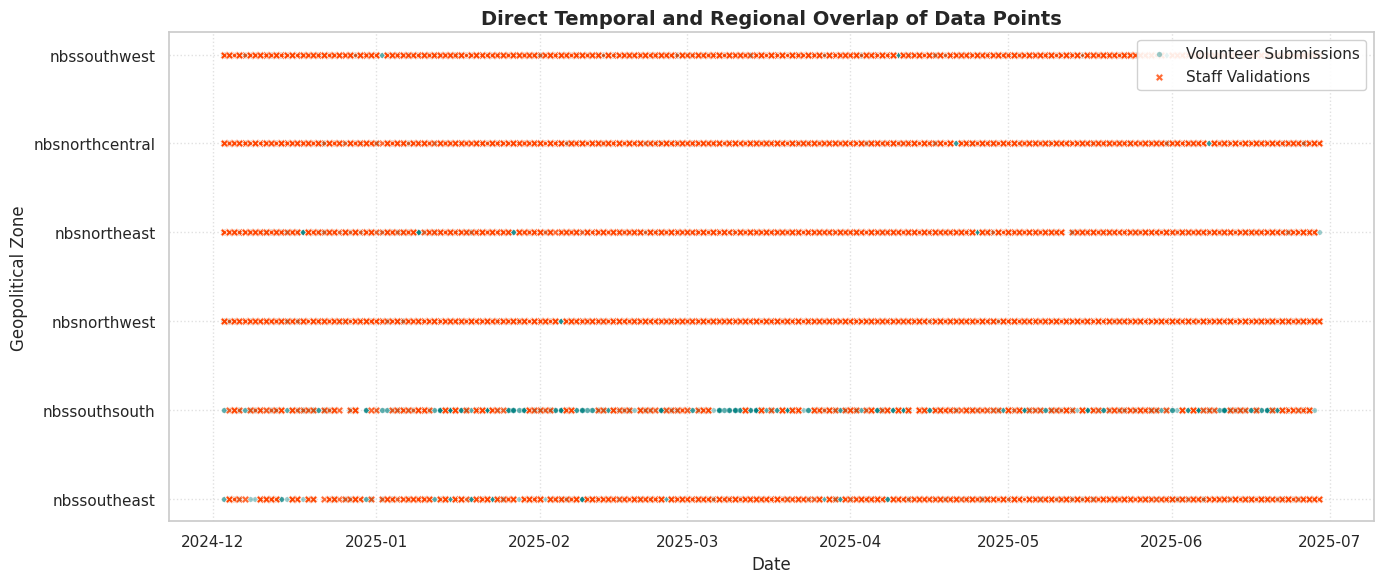

In [25]:

# Create a sample to make the plot clean and responsive
sample_val = staff_df.sample(n=min(5000, len(staff_df)), random_state=42)
sample_vol = volunteer_df.sample(n=min(5000, len(volunteer_df)), random_state=42)

plt.figure(figsize=(14, 6))

# Scatter plot of volunteer submissions with jitter on y-axis for better visibility
sns.scatterplot(
    data=sample_vol,
    x='date',
    y='geopol_zon',
    color='teal',
    alpha=0.4,
    s=15,
    label='Volunteer Submissions'
)

# Scatter plot of staff validation submissions
sns.scatterplot(
    data=sample_val,
    x='date',
    y='geopol_zon',
    color='orangered',
    alpha=0.8,
    s=30,
    marker='X',
    label='Staff Validations'
)

plt.title('Direct Temporal and Regional Overlap of Data Points', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Geopolitical Zone', fontsize=12)
plt.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### 11. Creating a Continuous Hybrid Dataset (Staff Prioritized with Volunteer Fallback)

We will construct a continuous date timeline spanning from the minimum to the maximum date in our dataset. For each date:
1. We will use the daily mean price from **staff validation data** if available.
2. If staff validation data is missing for a specific date, we will fall back and fill it with the **volunteer (crowdsourced) daily mean price**.

In [26]:
import pandas as pd
import numpy as np

# 1. Calculate daily average prices for both staff and volunteers
staff_daily_mean = staff_df.groupby('date')['price'].mean().rename('staff_price')
volunteer_daily_mean = volunteer_df.groupby('date')['price'].mean().rename('volunteer_price')

# 2. Generate a complete, continuous sequence of daily dates
full_date_range = pd.date_range(start=model_df['date'].min(), end=model_df['date'].max(), freq='D')

# 3. Build the hybrid DataFrame
hybrid_df = pd.DataFrame(index=full_date_range)
hybrid_df.index.name = 'date'

# Join our calculated daily means
hybrid_df = hybrid_df.join(staff_daily_mean, how='left')
hybrid_df = hybrid_df.join(volunteer_daily_mean, how='left')

# 4. Fill missing staff prices with volunteer prices
hybrid_df['hybrid_price'] = hybrid_df['staff_price'].combine_first(hybrid_df['volunteer_price'])

# Reset index to make date a column
hybrid_df = hybrid_df.reset_index()

# Display the top rows and summary information
print(f"Shape of Hybrid Dataset: {hybrid_df.shape}")
print(f"Number of missing dates in staff data: {hybrid_df['staff_price'].isna().sum()}")
print(f"Number of missing dates remaining in hybrid data: {hybrid_df['hybrid_price'].isna().sum()}")
display(hybrid_df.head(15))

Shape of Hybrid Dataset: (209, 4)
Number of missing dates in staff data: 0
Number of missing dates remaining in hybrid data: 0


,date,staff_price,volunteer_price,hybrid_price
0,2024-12-03,1976.305103,1934.897800,1976.305103
1,2024-12-04,1921.342857,1879.795348,1921.342857
2,2024-12-05,1762.442529,1951.198837,1762.442529
3,2024-12-06,1769.641314,1988.269081,1769.641314
4,2024-12-07,1694.046950,1895.458043,1694.046950
5,2024-12-08,1758.729069,1945.212817,1758.729069
6,2024-12-09,1730.368186,2020.442422,1730.368186
7,2024-12-10,1799.397894,1870.843801,1799.397894
8,2024-12-11,1850.552914,1948.257694,1850.552914
9,2024-12-12,1710.564356,1888.504337,1710.564356


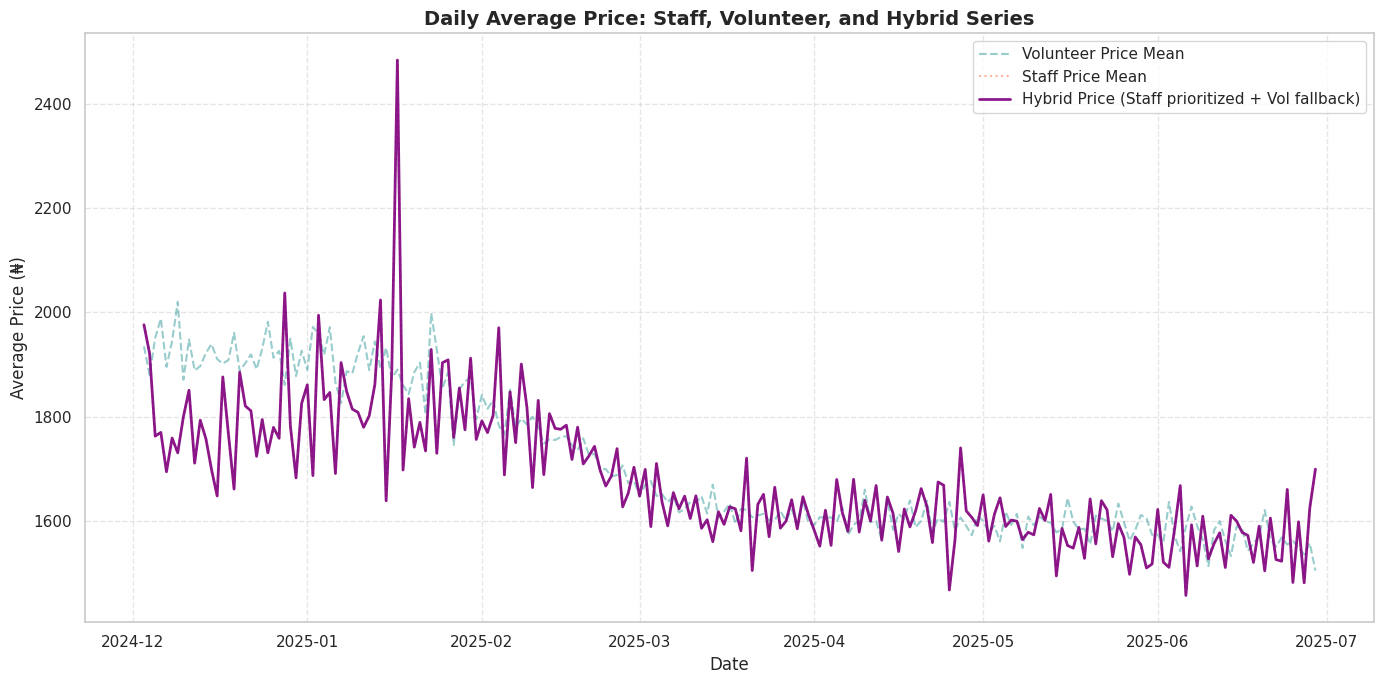

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))

# Plot individual source series for visual reference
plt.plot(hybrid_df['date'], hybrid_df['volunteer_price'], label='Volunteer Price Mean', color='teal', alpha=0.4, linestyle='--')
plt.plot(hybrid_df['date'], hybrid_df['staff_price'], label='Staff Price Mean', color='orangered', alpha=0.4, linestyle=':')

# Highlight the final hybridized result
plt.plot(hybrid_df['date'], hybrid_df['hybrid_price'], label='Hybrid Price (Staff prioritized + Vol fallback)', color='purple', linewidth=2, alpha=0.9)

plt.title('Daily Average Price: Staff, Volunteer, and Hybrid Series', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Average Price (₦)', fontsize=12)
plt.legend(fontsize=11, loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 12. Temporal Splitting of Data (Train, Validation, Test)

Since price forecasting and trend analysis are highly dependent on time, we split our data chronologically to ensure that our models are always evaluated on "future" data relative to what they were trained on.

We will define the split boundaries based on our total 209-day span:
* **Train:** First 70% of days
* **Validation:** Next 15% of days
* **Test:** Remaining 15% of days

In [28]:
import pandas as pd

# 1. Determine date boundaries from the hybrid timeline
unique_dates = sorted(hybrid_df['date'].unique())
total_days = len(unique_dates)

train_end_idx = int(total_days * 0.70)
val_end_idx = int(total_days * 0.85)

train_cutoff_date = unique_dates[train_end_idx]
val_cutoff_date = unique_dates[val_end_idx]

print(f"Timeline boundaries calculated:")
print(f"  - Training Period:   {unique_dates[0].strftime('%Y-%m-%d')} to {unique_dates[train_end_idx-1].strftime('%Y-%m-%d')} ({train_end_idx} days)")
print(f"  - Validation Period: {train_cutoff_date.strftime('%Y-%m-%d')} to {unique_dates[val_end_idx-1].strftime('%Y-%m-%d')} ({val_end_idx - train_end_idx} days)")
print(f"  - Testing Period:    {val_cutoff_date.strftime('%Y-%m-%d')} to {unique_dates[-1].strftime('%Y-%m-%d')} ({total_days - val_end_idx} days)")

Timeline boundaries calculated:
  - Training Period:   2024-12-03 to 2025-04-27 (146 days)
  - Validation Period: 2025-04-28 to 2025-05-28 (31 days)
  - Testing Period:    2025-05-29 to 2025-06-29 (32 days)


In [29]:
# 2. Apply split to the Daily Hybrid Dataset (hybrid_df)
hybrid_train = hybrid_df[hybrid_df['date'] < train_cutoff_date].copy()
hybrid_val = hybrid_df[(hybrid_df['date'] >= train_cutoff_date) & (hybrid_df['date'] < val_cutoff_date)].copy()
hybrid_test = hybrid_df[hybrid_df['date'] >= val_cutoff_date].copy()

print("--- Hybrid Time Series Splits ---")
print(f"Train shape: {hybrid_train.shape}")
print(f"Val shape:   {hybrid_val.shape}")
print(f"Test shape:  {hybrid_test.shape}\n")

# 3. Apply split to the Individual Records Dataset (model_df)
model_train = model_df[model_df['date'] < train_cutoff_date].copy()
model_val = model_df[(model_df['date'] >= train_cutoff_date) & (model_df['date'] < val_cutoff_date)].copy()
model_test = model_df[model_df['date'] >= val_cutoff_date].copy()

print("--- Individual Records Splits ---")
print(f"Train shape: {model_train.shape}")
print(f"Val shape:   {model_val.shape}")
print(f"Test shape:  {model_test.shape}")

--- Hybrid Time Series Splits ---
Train shape: (146, 4)
Val shape:   (31, 4)
Test shape:  (32, 4)

--- Individual Records Splits ---
Train shape: (140658, 10)
Val shape:   (30869, 10)
Test shape:  (30532, 10)


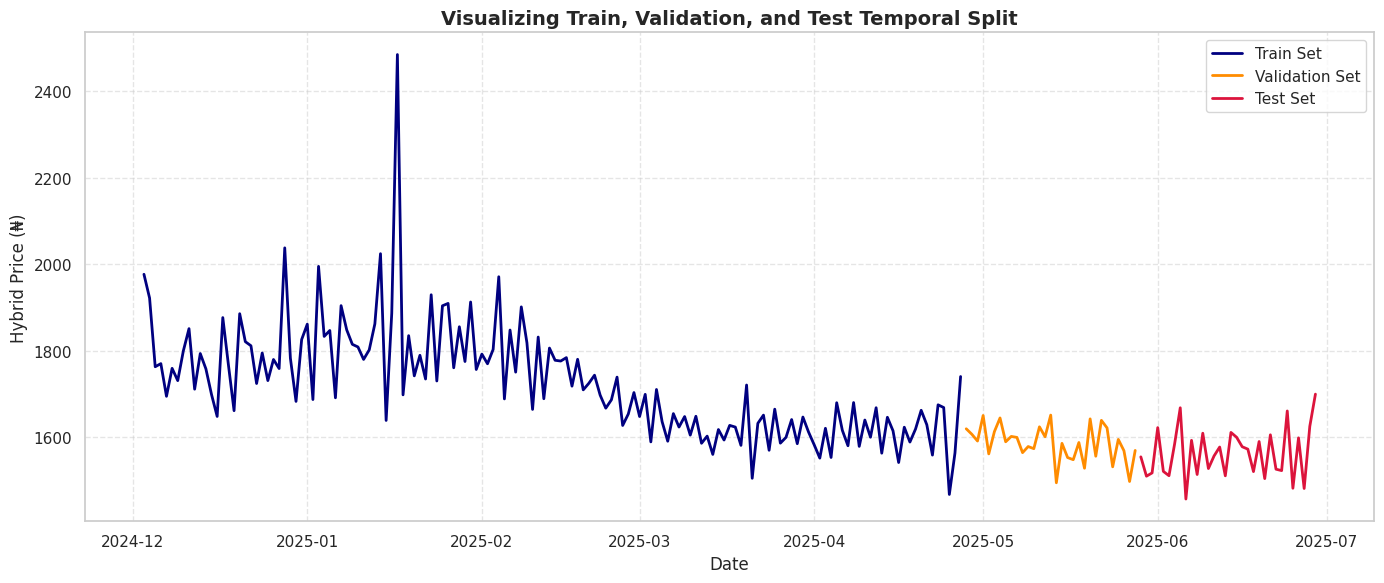

In [30]:
import matplotlib.pyplot as plt

# Visualize the split across our target hybrid_price series
plt.figure(figsize=(14, 6))

plt.plot(hybrid_train['date'], hybrid_train['hybrid_price'], label='Train Set', color='navy', linewidth=2)
plt.plot(hybrid_val['date'], hybrid_val['hybrid_price'], label='Validation Set', color='darkorange', linewidth=2)
plt.plot(hybrid_test['date'], hybrid_test['hybrid_price'], label='Test Set', color='crimson', linewidth=2)

plt.title('Visualizing Train, Validation, and Test Temporal Split', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Hybrid Price (₦)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 13. Training a Baseline Linear Regression Model on the Hybrid Series

To apply Linear Regression to a daily time series, we must construct lag features (using historical price values as input features). We will construct:
* `lag_1`: Yesterday's price
* `lag_2`: Price 2 days ago
* `lag_7`: Price 1 week ago

We will train the model on the training set splits, evaluate on the validation set to calculate RMSE, and perform a final check on our test split.

In [31]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# 1. Feature Engineering: Create Lags on the entire hybrid series to avoid missing history at boundary starts
hybrid_features = hybrid_df.copy()
hybrid_features['lag_1'] = hybrid_features['hybrid_price'].shift(1)
hybrid_features['lag_2'] = hybrid_features['hybrid_price'].shift(2)
hybrid_features['lag_7'] = hybrid_features['hybrid_price'].shift(7)

# Drop rows with NaN caused by shifting
hybrid_features = hybrid_features.dropna().reset_index(drop=True)

# 2. Re-apply the temporal splits on the newly engineered feature set
train_feats = hybrid_features[hybrid_features['date'] < train_cutoff_date]
val_feats = hybrid_features[(hybrid_features['date'] >= train_cutoff_date) & (hybrid_features['date'] < val_cutoff_date)]
test_feats = hybrid_features[hybrid_features['date'] >= val_cutoff_date]

# Define our target and features
X_cols = ['lag_1', 'lag_2', 'lag_7']
y_col = 'hybrid_price'

X_train, y_train = train_feats[X_cols], train_feats[y_col]
X_val, y_val = val_feats[X_cols], val_feats[y_col]
X_test, y_test = test_feats[X_cols], test_feats[y_col]

print(f"Training features shape: {X_train.shape}")
print(f"Validation features shape: {X_val.shape}")
print(f"Testing features shape: {X_test.shape}")

Training features shape: (139, 3)
Validation features shape: (31, 3)
Testing features shape: (32, 3)


In [38]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# 3. Instantiate and train our standard Linear Regression baseline model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 4. Predict on Validation and Test sets
y_pred_val = lr_model.predict(X_val)
y_pred_test = lr_model.predict(X_test)

# 5. Evaluate performance using Root Mean Squared Error (RMSE)
val_rmse = np.sqrt(mean_squared_error(y_val, y_pred_val))
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))

print(f"--- Linear Regression Baseline Performance ---")
print(f"Validation Set RMSE: {val_rmse:.2f} ₦")
print(f"Test Set RMSE:       {test_rmse:.2f} ₦")

--- Linear Regression Baseline Performance ---
Validation Set RMSE: 52.75 ₦
Test Set RMSE:       67.35 ₦


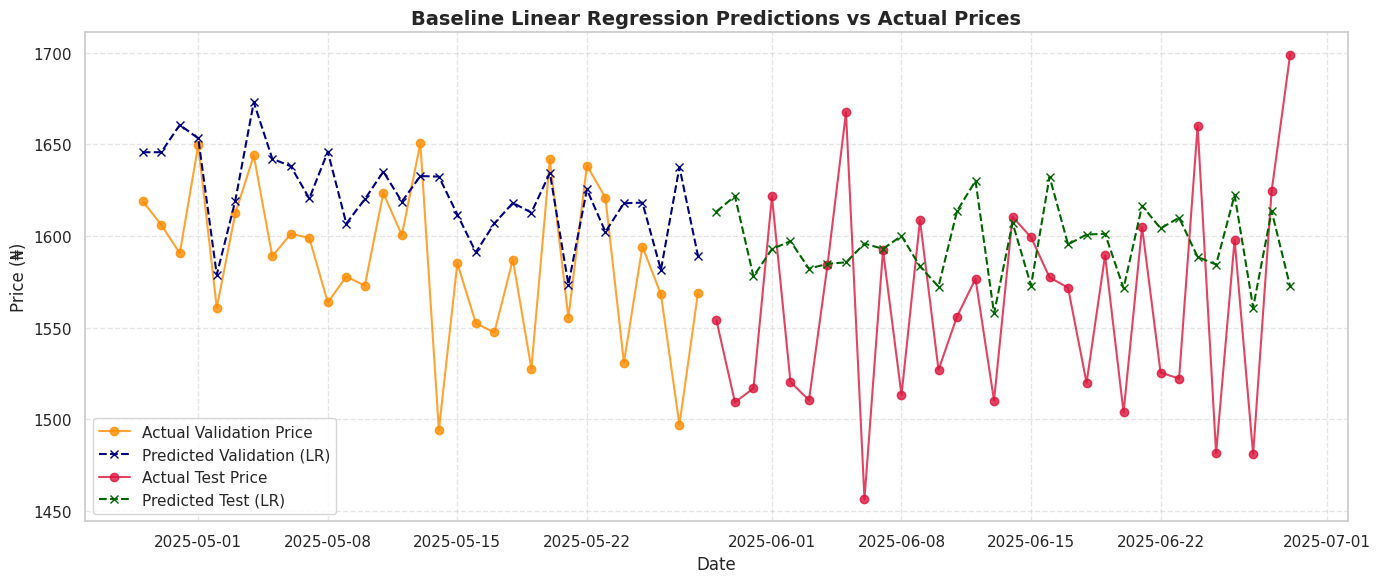

In [33]:
# Plot the predictions against ground truth
plt.figure(figsize=(14, 6))

# Plot validation set ground truth vs predictions
plt.plot(val_feats['date'], y_val, label='Actual Validation Price', color='darkorange', marker='o', alpha=0.8)
plt.plot(val_feats['date'], y_pred_val, label='Predicted Validation (LR)', color='navy', linestyle='--', marker='x')

# Plot test set ground truth vs predictions
plt.plot(test_feats['date'], y_test, label='Actual Test Price', color='crimson', marker='o', alpha=0.8)
plt.plot(test_feats['date'], y_pred_test, label='Predicted Test (LR)', color='darkgreen', linestyle='--', marker='x')

plt.title('Baseline Linear Regression Predictions vs Actual Prices', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (₦)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [39]:
import numpy as np
from sklearn.metrics import mean_squared_error

# 1. Naive Benchmark (predicting today's price is the same as yesterday's, i.e., lag_1)
naive_pred_val = X_val['lag_1']
naive_pred_test = X_test['lag_1']

naive_val_rmse = np.sqrt(mean_squared_error(y_val, naive_pred_val))
naive_test_rmse = np.sqrt(mean_squared_error(y_test, naive_pred_test))

# 2. Mean Benchmark (predicting the constant mean of the training set)
train_mean_value = y_train.mean()
mean_pred_val = np.full_like(y_val, fill_value=train_mean_value)
mean_pred_test = np.full_like(y_test, fill_value=train_mean_value)

mean_val_rmse = np.sqrt(mean_squared_error(y_val, mean_pred_val))
mean_test_rmse = np.sqrt(mean_squared_error(y_test, mean_pred_test))

print("=== baseline comparison metrics ===")
print(f"Training Mean Target Price: {train_mean_value:.2f} ₦\n")

print(f"[Mean Baseline] (Predicting constant training mean of {train_mean_value:.2f} ₦)")
print(f"  Validation RMSE : {mean_val_rmse:.2f} ₦")
print(f"  Test RMSE       : {mean_test_rmse:.2f} ₦\n")

print(f"[Naive Baseline] (Predicting yesterday's price 'lag_1')")
print(f"  Validation RMSE : {naive_val_rmse:.2f} ₦")
print(f"  Test RMSE       : {naive_test_rmse:.2f} ₦\n")

print(f"[Your Linear Regression Model]")
print(f"  Validation RMSE : {val_rmse:.2f} ₦ ({(1 - val_rmse/mean_val_rmse)*100:.1f}% improvement over mean)")
print(f"  Test RMSE       : {test_rmse:.2f} ₦ ({(1 - test_rmse/mean_test_rmse)*100:.1f}% improvement over mean)")

=== baseline comparison metrics ===
Training Mean Target Price: 1720.29 ₦

[Mean Baseline] (Predicting constant training mean of 1720.29 ₦)
  Validation RMSE : 140.17 ₦
  Test RMSE       : 168.22 ₦

[Naive Baseline] (Predicting yesterday's price 'lag_1')
  Validation RMSE : 64.77 ₦
  Test RMSE       : 92.43 ₦

[Your Linear Regression Model]
  Validation RMSE : 52.75 ₦ (62.4% improvement over mean)
  Test RMSE       : 67.35 ₦ (60.0% improvement over mean)
